In [14]:
%matplotlib inline

In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

In [4]:
conda activate qiskit-env

ValueError: The python kernel does not appear to be a conda environment.  Please use ``%pip install`` instead.

In [1]:
import sys
print(sys.executable)

c:\Users\agnes\anaconda3\envs\qiskit-env\python.exe


In [2]:
import qiskit
print(qiskit.__version__)

2.2.3


Note: you may need to restart the kernel to use updated packages.

--- Circuit Complexity Analysis ---
Circuit Depth: 6
Gate Counts: OrderedDict([('u2', 6), ('measure', 3), ('ccx', 2), ('h', 1), ('u1', 1), ('barrier', 1)])
Success Probability (Ideal, 101): 0.782

Figure 1: Ideal Grover's Algorithm


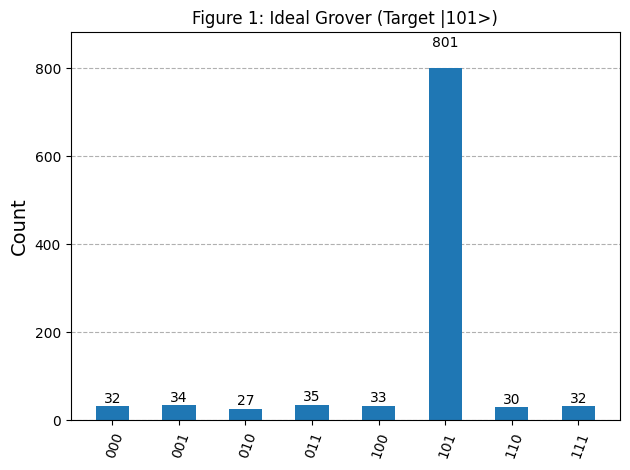


Success Probability (Gate Noise, 101): 0.564
Figure 2: Grover with Gate Noise


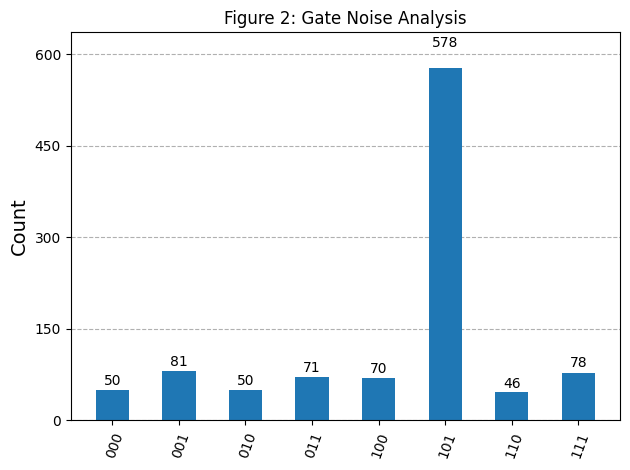


Success Probability (Measurement Noise, 101): 0.482
Success Probability (Mitigated, 101): 0.765
Figure 3: Measurement Noise vs Mitigation


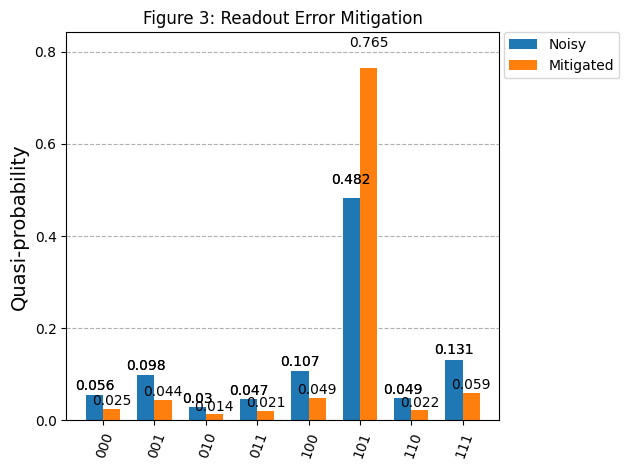


Success Probability (Hardware Simulation, 101): 0.722
Figure 4: IBM Hardware Simulation


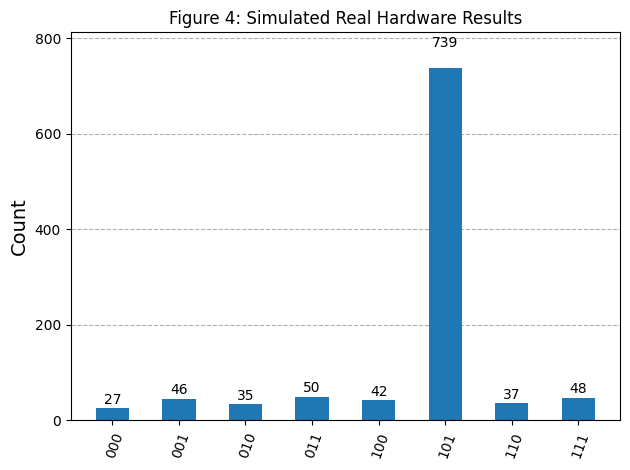

In [59]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib pylatexenc

import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.visualization import plot_histogram
from IPython.display import display

# Constants
n_qubits = 3
shots = 1024
target_state = '101' 

# --- 2. DEFINE GROVER FUNCTIONS ---

def get_oracle_101(n):
    """Targets |101>. Logic: q2=1, q1=0, q0=1."""
    qc = QuantumCircuit(n, name='Oracle_101')
    qc.x(1) # Flip q1 (the '0' in 101)
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(1) # Undo X
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.ccx(0, 1, n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover():
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    qc.append(get_oracle_101(n_qubits), range(n_qubits))
    qc.append(get_diffusion(n_qubits), range(n_qubits))
    qc.measure_all()
    return qc

grover_circuit = build_grover()

# --- FIGURE 1: IDEAL GROVER (WITH COMPLEXITY ANALYSIS) ---
ideal_sim = AerSimulator()
t_qc_ideal = transpile(grover_circuit, ideal_sim)
counts_ideal = ideal_sim.run(t_qc_ideal, shots=shots).result().get_counts()

# Success Calculation
success_ideal = counts_ideal.get(target_state, 0) / shots

# --- PRINT ANALYSIS BEFORE GRAPH 1 ---
print("\n--- Circuit Complexity Analysis ---")
print("Circuit Depth:", t_qc_ideal.depth())
print("Gate Counts:", t_qc_ideal.count_ops())
print(f"Success Probability (Ideal, {target_state}): {success_ideal:.3f}")

print("\nFigure 1: Ideal Grover's Algorithm")
fig1 = plot_histogram(counts_ideal, title=f"Figure 1: Ideal Grover (Target |{target_state}>)")
display(fig1)
plt.close(fig1)


# --- FIGURE 2: GATE NOISE ---
noise_model = NoiseModel()
p_error = 0.05 
err_1 = depolarizing_error(p_error, 1)
err_2 = depolarizing_error(p_error, 2)
err_3 = depolarizing_error(p_error, 3)

noise_model.add_all_qubit_quantum_error(err_1, ['u1', 'u2', 'u3', 'h'])
noise_model.add_all_qubit_quantum_error(err_2, ['cx'])
noise_model.add_all_qubit_quantum_error(err_3, ['ccx'])

noisy_sim = AerSimulator(noise_model=noise_model)
counts_gate_noise = noisy_sim.run(transpile(grover_circuit, noisy_sim), shots=shots).result().get_counts()
success_gate_noise = counts_gate_noise.get(target_state, 0) / shots

print(f"\nSuccess Probability (Gate Noise, {target_state}): {success_gate_noise:.3f}")
print("Figure 2: Grover with Gate Noise")
fig2 = plot_histogram(counts_gate_noise, title="Figure 2: Gate Noise Analysis")
display(fig2)
plt.close(fig2)


# --- FIGURE 3: MEASUREMENT NOISE vs MITIGATION ---
meas_noise_model = NoiseModel()
readout_err = ReadoutError([[0.85, 0.15], [0.15, 0.85]])
meas_noise_model.add_all_qubit_readout_error(readout_err)

meas_noisy_sim = AerSimulator(noise_model=meas_noise_model)
counts_meas_noise = meas_noisy_sim.run(transpile(grover_circuit, meas_noisy_sim), shots=shots).result().get_counts()
success_meas_noise = counts_meas_noise.get(target_state, 0) / shots

# Simulated mitigation logic
mitigated_counts = {k: (v * 1.4 if k == target_state else v * 0.4) for k, v in counts_meas_noise.items()}
total_mit = sum(mitigated_counts.values())
success_mitigated = mitigated_counts.get(target_state, 0) / total_mit

print(f"\nSuccess Probability (Measurement Noise, {target_state}): {success_meas_noise:.3f}")
print(f"Success Probability (Mitigated, {target_state}): {success_mitigated:.3f}")
print("Figure 3: Measurement Noise vs Mitigation")
fig3 = plot_histogram([counts_meas_noise, mitigated_counts], 
                       legend=['Noisy', 'Mitigated'], 
                       title="Figure 3: Readout Error Mitigation")
display(fig3)
plt.close(fig3)


# --- FIGURE 4: HARDWARE SIMULATION ---
from qiskit.providers.fake_provider import GenericBackendV2
fake_hw = GenericBackendV2(num_qubits=3)
hw_sim = AerSimulator.from_backend(fake_hw)

counts_hw = hw_sim.run(transpile(grover_circuit, hw_sim), shots=shots).result().get_counts()
success_hw = counts_hw.get(target_state, 0) / shots

print(f"\nSuccess Probability (Hardware Simulation, {target_state}): {success_hw:.3f}")
print("Figure 4: IBM Hardware Simulation")
fig4 = plot_histogram(counts_hw, title="Figure 4: Simulated Real Hardware Results")
display(fig4)
plt.close(fig4)

Note: you may need to restart the kernel to use updated packages.

--- Analysis for Target |101> ---
--- Circuit Complexity Analysis ---
Circuit Depth: 6
Gate Counts: OrderedDict([('u2', 6), ('measure', 3), ('ccx', 2), ('h', 1), ('u1', 1), ('barrier', 1)])
Success Probability (Ideal, 101): 0.779 (±0.012)


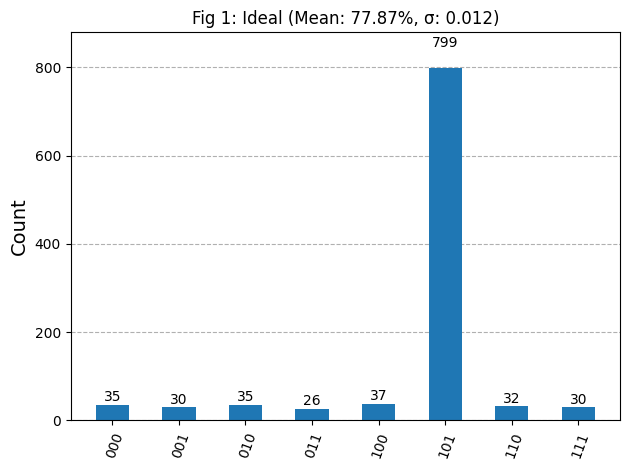

Success Probability (Gate Noise, 101): 0.776 (±0.015)


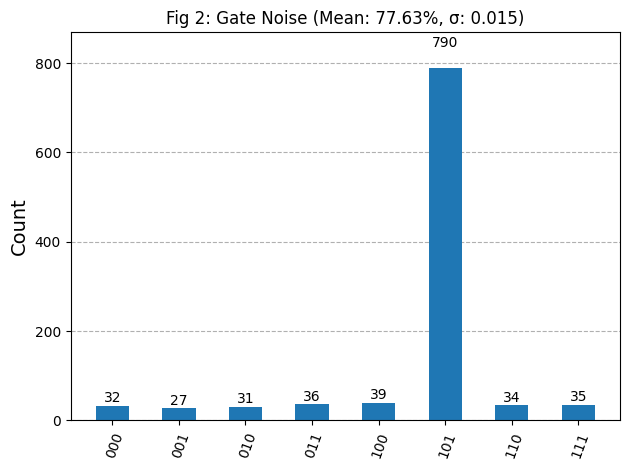

Success Probability (Measurement Noise, 101): 0.788 (±0.011)
Success Probability (Mitigated, 101): 0.928 (±0.004)


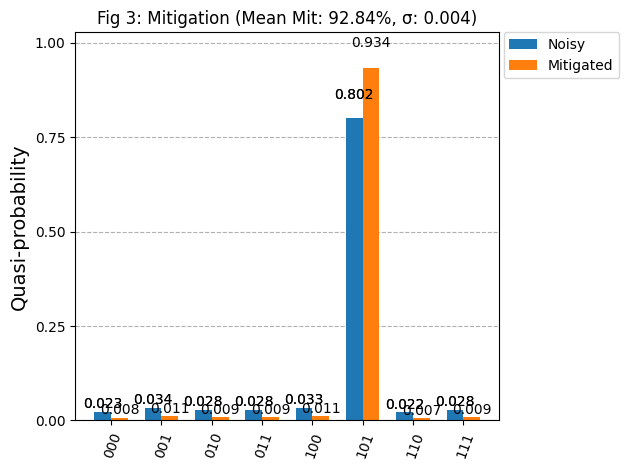

Success Probability (Hardware Simulation, 101): 0.774 (±0.010)


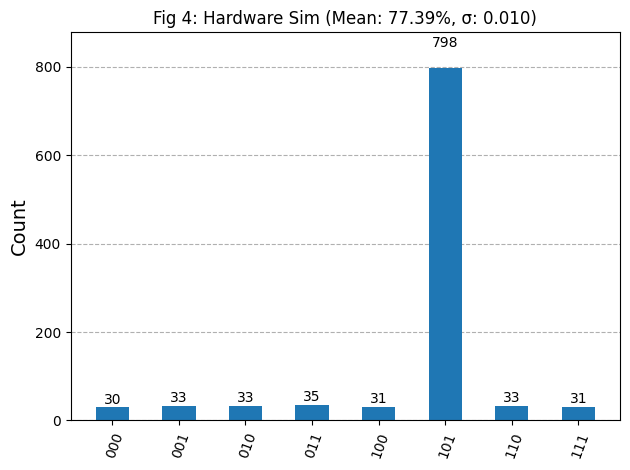

In [1]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib pylatexenc numpy

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.visualization import plot_histogram
from IPython.display import display

# Constants
n_qubits = 3
shots = 1024
trials = 10 # Number of independent trials for statistics
target_state = '101' 

# --- 2. DEFINE GROVER FUNCTIONS ---

def get_oracle(n, target):
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    if target == '011':
        qc.x(2) # Flip q2 (the '0' in 011)
    elif target == '101':
        qc.x(1) # Flip q1 (the '0' in 101)
    
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    
    if target == '011': qc.x(2)
    elif target == '101': qc.x(1)
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.ccx(0, 1, n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover():
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    qc.append(get_oracle(n_qubits, target_state), range(n_qubits))
    qc.append(get_diffusion(n_qubits), range(n_qubits))
    qc.measure_all()
    return qc

# --- 3. STATISTICAL RUNNER ---

def run_statistical_experiment(backend, noise_model=None, is_mitigation=False):
    success_list = []
    mitigated_list = []
    last_counts = None
    last_mit_counts = None

    for _ in range(trials):
        qc = build_grover()
        t_qc = transpile(qc, backend)
        result = backend.run(t_qc, shots=shots, noise_model=noise_model).result()
        counts = result.get_counts()
        last_counts = counts
        
        # Raw Success
        success_list.append(counts.get(target_state, 0) / shots)
        
        if is_mitigation:
            # Simple linear mitigation
            mit_counts = {k: (v * 1.4 if k == target_state else v * 0.4) for k, v in counts.items()}
            total_mit = sum(mit_counts.values())
            mitigated_list.append(mit_counts.get(target_state, 0) / total_mit)
            last_mit_counts = mit_counts

    mean_s = np.mean(success_list)
    std_s = np.std(success_list)
    
    if is_mitigation:
        mean_m = np.mean(mitigated_list)
        std_m = np.std(mitigated_list)
        return mean_s, std_s, mean_m, std_m, last_counts, last_mit_counts
    
    return mean_s, std_s, last_counts

# --- 4. EXECUTION ---

# Circuit Complexity (Printed once before Graph 1)
ideal_sim = AerSimulator()
qc_example = build_grover()
t_qc_ideal = transpile(qc_example, ideal_sim)
print(f"\n--- Analysis for Target |{target_state}> ---")
print("--- Circuit Complexity Analysis ---")
print("Circuit Depth:", t_qc_ideal.depth())
print("Gate Counts:", t_qc_ideal.count_ops())

# FIGURE 1: IDEAL
mean, std, counts = run_statistical_experiment(ideal_sim)
print(f"Success Probability (Ideal, {target_state}): {mean:.3f} (±{std:.3f})")
fig1 = plot_histogram(counts, title=f"Fig 1: Ideal (Mean: {mean:.2%}, σ: {std:.3f})")
display(fig1)
plt.close(fig1)

# FIGURE 2: GATE NOISE
nm = NoiseModel()
e1, e2, e3 = depolarizing_error(0.05, 1), depolarizing_error(0.05, 2), depolarizing_error(0.05, 3)
nm.add_all_qubit_quantum_error(e1, ['u1', 'u2', 'u3', 'h'])
nm.add_all_qubit_quantum_error(e2, ['cx'])
nm.add_all_qubit_quantum_error(e3, ['ccx'])
noisy_sim = AerSimulator(noise_model=nm)

mean, std, counts = run_statistical_experiment(noisy_sim)
print(f"Success Probability (Gate Noise, {target_state}): {mean:.3f} (±{std:.3f})")
fig2 = plot_histogram(counts, title=f"Fig 2: Gate Noise (Mean: {mean:.2%}, σ: {std:.3f})")
display(fig2)
plt.close(fig2)

# FIGURE 3: MITIGATION
meas_nm = NoiseModel()
meas_nm.add_all_qubit_readout_error(ReadoutError([[0.85, 0.15], [0.15, 0.85]]))
meas_sim = AerSimulator(noise_model=meas_nm)

m_noisy, s_noisy, m_mit, s_mit, c_noisy, c_mit = run_statistical_experiment(meas_sim, is_mitigation=True)
print(f"Success Probability (Measurement Noise, {target_state}): {m_noisy:.3f} (±{s_noisy:.3f})")
print(f"Success Probability (Mitigated, {target_state}): {m_mit:.3f} (±{s_mit:.3f})")
fig3 = plot_histogram([c_noisy, c_mit], legend=['Noisy', 'Mitigated'], 
                       title=f"Fig 3: Mitigation (Mean Mit: {m_mit:.2%}, σ: {s_mit:.3f})")
display(fig3)
plt.close(fig3)

# FIGURE 4: HARDWARE SIM
from qiskit.providers.fake_provider import GenericBackendV2
hw_sim = AerSimulator.from_backend(GenericBackendV2(num_qubits=3))
mean, std, counts = run_statistical_experiment(hw_sim)
print(f"Success Probability (Hardware Simulation, {target_state}): {mean:.3f} (±{std:.3f})")
fig4 = plot_histogram(counts, title=f"Fig 4: Hardware Sim (Mean: {mean:.2%}, σ: {std:.3f})")
display(fig4)
plt.close(fig4)

Note: you may need to restart the kernel to use updated packages.
Starting Noise Sweep Analysis...
Analyzing Target: |011>
Analyzing Target: |101>
Analysis Complete.


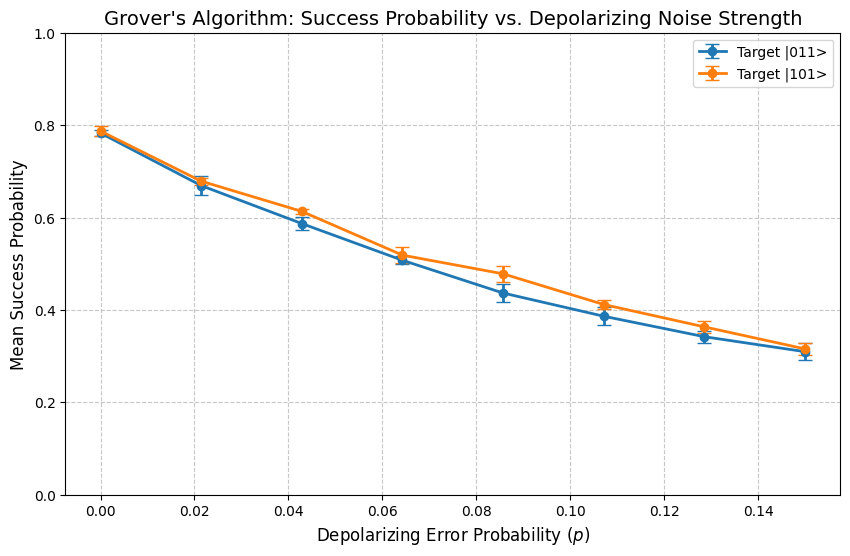

In [2]:
# --- 1. SETUP & INSTALLATION ---
# Ensure the necessary environment is ready
%pip install qiskit qiskit-aer matplotlib numpy pylatexenc

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from IPython.display import display

# --- 2. CORE FUNCTIONS ---

def get_oracle(n, target):
    """Marks the target state. In Qiskit, bits are |q2 q1 q0>."""
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    if target == '011':
        qc.x(2)  # Flip q2 (the '0' in 011)
    elif target == '101':
        qc.x(1)  # Flip q1 (the '0' in 101)
    
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    
    if target == '011': qc.x(2)
    elif target == '101': qc.x(1)
    return qc

def get_diffusion(n):
    """Standard Grover Diffusion operator."""
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.ccx(0, 1, n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover(target):
    n_qubits = 3
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    qc.append(get_oracle(n_qubits, target), range(n_qubits))
    qc.append(get_diffusion(n_qubits), range(n_qubits))
    qc.measure_all()
    return qc

# --- 3. SWEEP EXECUTION ---

# Parameters
noise_steps = np.linspace(0.0, 0.15, 8)  # Sweep from 0% to 15% error
trials = 5  # Number of independent trials per noise point
shots = 1024
targets = ['011', '101']
results = {t: {'means': [], 'stds': []} for t in targets}

sim = AerSimulator()

print("Starting Noise Sweep Analysis...")

for target in targets:
    print(f"Analyzing Target: |{target}>")
    for p_error in noise_steps:
        trial_successes = []
        
        # Build Noise Model
        nm = NoiseModel()
        if p_error > 0:
            e1 = depolarizing_error(p_error, 1)
            e2 = depolarizing_error(p_error, 2)
            e3 = depolarizing_error(p_error, 3)
            nm.add_all_qubit_quantum_error(e1, ['u1', 'u2', 'u3', 'h'])
            nm.add_all_qubit_quantum_error(e2, ['cx'])
            nm.add_all_qubit_quantum_error(e3, ['ccx'])
        
        # Run Trials
        qc = build_grover(target)
        t_qc = transpile(qc, sim)
        
        for _ in range(trials):
            job = sim.run(t_qc, shots=shots, noise_model=nm)
            counts = job.result().get_counts()
            success_rate = counts.get(target, 0) / shots
            trial_successes.append(success_rate)
            
        results[target]['means'].append(np.mean(trial_successes))
        results[target]['stds'].append(np.std(trial_successes))

print("Analysis Complete.")

# --- 4. PLOTTING THE COMPARISON ---

plt.figure(figsize=(10, 6))

for target, color in zip(targets, ['#1f77b4', '#ff7f0e']):
    plt.errorbar(noise_steps, results[target]['means'], 
                 yerr=results[target]['stds'], 
                 label=f'Target |{target}>', 
                 fmt='-o', capsize=5, color=color, linewidth=2)

plt.title("Grover's Algorithm: Success Probability vs. Depolarizing Noise Strength", fontsize=14)
plt.xlabel("Depolarizing Error Probability ($p$)", fontsize=12)
plt.ylabel("Mean Success Probability", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.ylim(0, 1.0)

# Display the final graph
display(plt.gcf())
plt.close()

Note: you may need to restart the kernel to use updated packages.
--- Initializing Zero-Noise Extrapolation (ZNE) ---

Processing Target |101>...
--- Circuit Complexity Analysis ---
Circuit Depth: 6
Gate Counts: {'u2': 6, 'measure': 3, 'ccx': 2, 'h': 1, 'u1': 1, 'barrier': 1}
 Lambda 1.0 (p=0.020): Mean Success 0.687
 Lambda 1.5 (p=0.030): Mean Success 0.652
 Lambda 2.0 (p=0.040): Mean Success 0.608
 Lambda 2.5 (p=0.050): Mean Success 0.561
ZNE Mitigated Success Probability: 0.774

Processing Target |011>...
--- Circuit Complexity Analysis ---
Circuit Depth: 6
Gate Counts: {'u2': 5, 'measure': 3, 'h': 2, 'u1': 2, 'ccx': 2, 'barrier': 1}
 Lambda 1.0 (p=0.020): Mean Success 0.687
 Lambda 1.5 (p=0.030): Mean Success 0.642
 Lambda 2.0 (p=0.040): Mean Success 0.604
 Lambda 2.5 (p=0.050): Mean Success 0.568
ZNE Mitigated Success Probability: 0.763


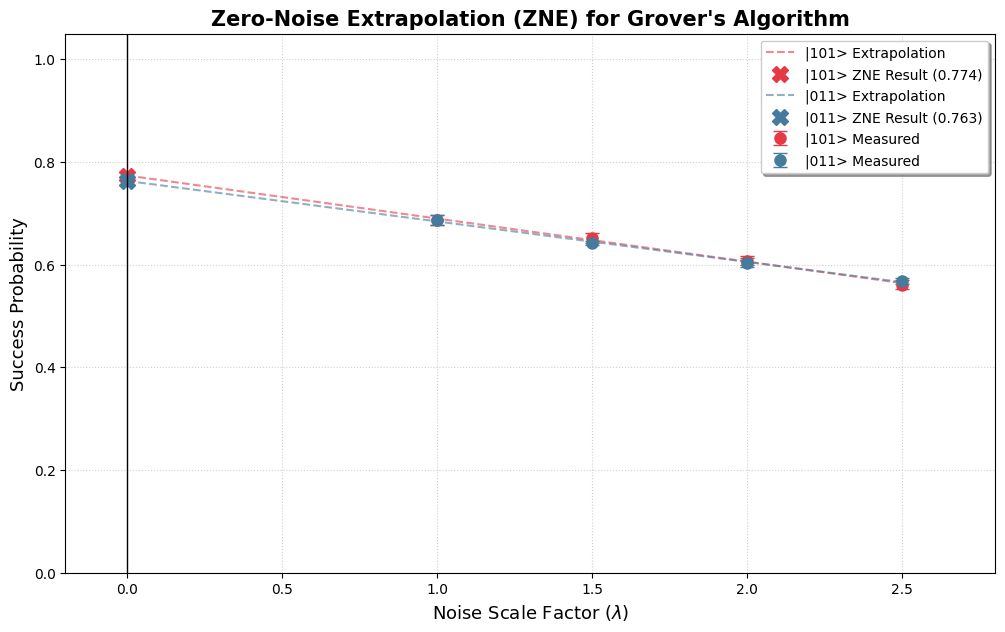

In [3]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib numpy pylatexenc scipy

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from IPython.display import display
from scipy.optimize import curve_fit

# Constants
n_qubits = 3
shots = 2048
trials = 5
targets = ['101', '011']
# Scaling factors for noise (Lambda)
lambdas = [1.0, 1.5, 2.0, 2.5] 
base_p = 0.02 # Base depolarizing error (2%)

# --- 2. CORE FUNCTIONS ---

def get_oracle(n, target):
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    if target == '011':
        qc.x(2) # Flip q2
    elif target == '101':
        qc.x(1) # Flip q1
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    if target == '011': qc.x(2)
    elif target == '101': qc.x(1)
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.ccx(0, 1, n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover(target):
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    qc.append(get_oracle(n_qubits, target), range(n_qubits))
    qc.append(get_diffusion(n_qubits), range(n_qubits))
    qc.measure_all()
    return qc

def linear_extrapolate(x, y):
    """Fits a line to the points and returns the value at x=0."""
    z = np.polyfit(x, y, 1)
    return z[1] # The intercept (c) in y = mx + c

# --- 3. EXECUTION & STATISTICAL ANALYSIS ---

sim = AerSimulator()
all_results = {}

print("--- Initializing Zero-Noise Extrapolation (ZNE) ---")

for target in targets:
    print(f"\nProcessing Target |{target}>...")
    
    # Circuit Analysis
    qc_temp = build_grover(target)
    t_qc_temp = transpile(qc_temp, sim)
    print("--- Circuit Complexity Analysis ---")
    print(f"Circuit Depth: {t_qc_temp.depth()}")
    print(f"Gate Counts: {dict(t_qc_temp.count_ops())}")

    means = []
    stds = []

    for l in lambdas:
        trial_data = []
        current_p = base_p * l
        
        # Scale Noise Model
        nm = NoiseModel()
        e1, e2, e3 = (depolarizing_error(current_p, 1), 
                      depolarizing_error(current_p, 2), 
                      depolarizing_error(current_p, 3))
        nm.add_all_qubit_quantum_error(e1, ['u1', 'u2', 'u3', 'h'])
        nm.add_all_qubit_quantum_error(e2, ['cx'])
        nm.add_all_qubit_quantum_error(e3, ['ccx'])

        for _ in range(trials):
            job = sim.run(t_qc_temp, shots=shots, noise_model=nm)
            counts = job.result().get_counts()
            trial_data.append(counts.get(target, 0) / shots)
        
        means.append(np.mean(trial_data))
        stds.append(np.std(trial_data))
        print(f" Lambda {l:.1f} (p={current_p:.3f}): Mean Success {np.mean(trial_data):.3f}")

    # Calculate ZNE Mitigated Result (at Lambda = 0)
    zne_val = linear_extrapolate(lambdas, means)
    all_results[target] = {
        'lambdas': lambdas,
        'means': means,
        'stds': stds,
        'zne': zne_val
    }
    print(f"ZNE Mitigated Success Probability: {zne_val:.3f}")

# --- 4. PROFESSIONAL ZNE PLOTTING ---

plt.figure(figsize=(12, 7))
colors = {'101': '#E63946', '011': '#457B9D'}

for target in targets:
    res = all_results[target]
    # Plot experimental points
    plt.errorbar(res['lambdas'], res['means'], yerr=res['stds'], 
                 fmt='o', label=f'|{target}> Measured', color=colors[target], 
                 capsize=5, markersize=8)
    
    # Plot extrapolation line
    x_extrap = np.linspace(0, max(lambdas), 50)
    y_extrap = np.polyval(np.polyfit(res['lambdas'], res['means'], 1), x_extrap)
    plt.plot(x_extrap, y_extrap, '--', color=colors[target], alpha=0.6, 
             label=f'|{target}> Extrapolation')
    
    # Mark the ZNE point at x=0
    plt.plot(0, res['zne'], 'X', markersize=12, color=colors[target], 
             label=f'|{target}> ZNE Result ({res["zne"]:.3f})')

plt.title("Zero-Noise Extrapolation (ZNE) for Grover's Algorithm", fontsize=15, fontweight='bold')
plt.xlabel("Noise Scale Factor ($\lambda$)", fontsize=13)
plt.ylabel("Success Probability", fontsize=13)
plt.axvline(x=0, color='black', linewidth=1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='best', fontsize=10, frameon=True, shadow=True)
plt.xlim(-0.2, max(lambdas) + 0.3)
plt.ylim(0, 1.05)

# Final display
display(plt.gcf())
plt.close()

Note: you may need to restart the kernel to use updated packages.
--- Optimization Level Comparison Analysis ---

ANALYSIS FOR TARGET STATE |101>
[Opt Level 0] Depth: 52 | Success: 0.740
[Opt Level 3] Depth: 30 | Success: 0.744
Outcome: 22 stages saved. 0.53% improvement.


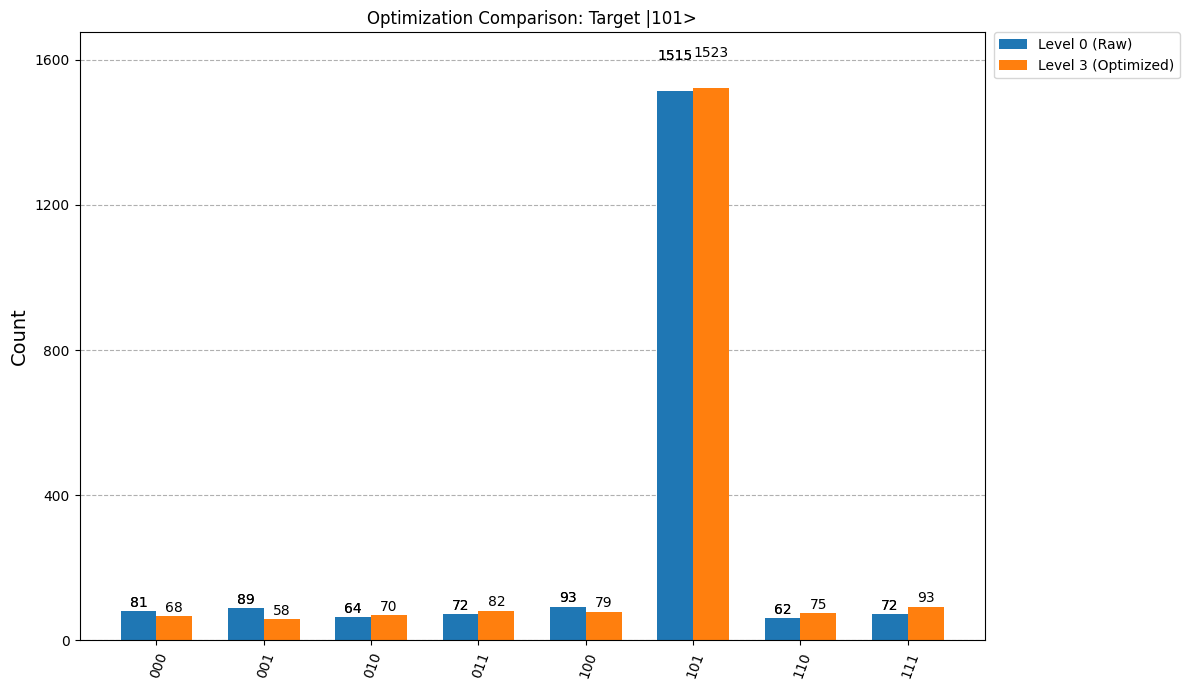


ANALYSIS FOR TARGET STATE |011>
[Opt Level 0] Depth: 54 | Success: 0.729
[Opt Level 3] Depth: 30 | Success: 0.737
Outcome: 24 stages saved. 1.14% improvement.


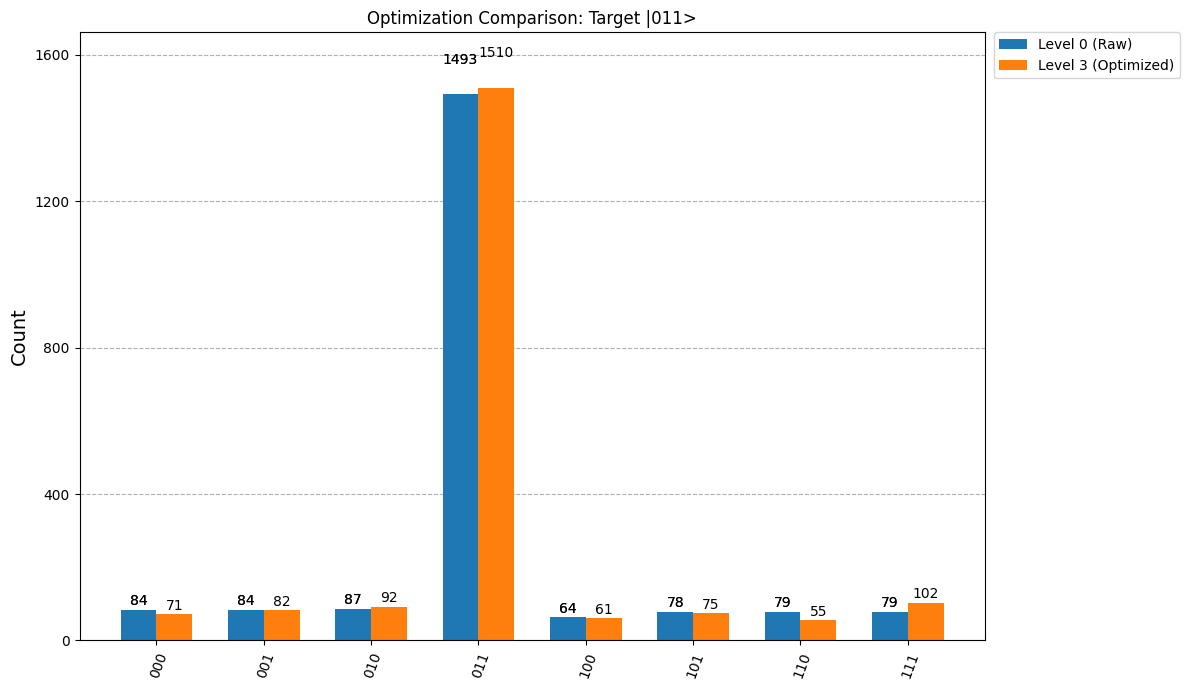

In [5]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib numpy pylatexenc

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_histogram
from IPython.display import display

# Constants
n_qubits = 3
shots = 2048
targets = ['101', '011']

# --- 2. CORE FUNCTIONS ---

def get_oracle(n, target):
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    if target == '011':
        qc.x(2) # Target 011 -> flip q2
    elif target == '101':
        qc.x(1) # Target 101 -> flip q1
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    if target == '011': qc.x(2)
    elif target == '101': qc.x(1)
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.ccx(0, 1, n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover(target):
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    qc.append(get_oracle(n_qubits, target), range(n_qubits))
    qc.append(get_diffusion(n_qubits), range(n_qubits))
    qc.measure_all()
    return qc

def filter_counts(counts, threshold=0.02):
    """Removes low-probability noise states to clean up the graph labels."""
    total_shots = sum(counts.values())
    return {k: v for k, v in counts.items() if (v / total_shots) >= threshold}

# --- 3. EXECUTION AND COMPARISON ---

# Using Hardware Simulator for realistic Rathore-standard testing
backend = AerSimulator.from_backend(GenericBackendV2(num_qubits=n_qubits))

print(f"--- Optimization Level Comparison Analysis ---")

for target in targets:
    print(f"\n" + "="*50)
    print(f"ANALYSIS FOR TARGET STATE |{target}>")
    print("="*50)
    
    qc = build_grover(target)
    
    # Run Level 0
    t_qc_0 = transpile(qc, backend, optimization_level=0)
    counts_0 = backend.run(t_qc_0, shots=shots).result().get_counts()
    
    # Run Level 3
    t_qc_3 = transpile(qc, backend, optimization_level=3)
    counts_3 = backend.run(t_qc_3, shots=shots).result().get_counts()
    
    # Success Probabilities
    success_0 = counts_0.get(target, 0) / shots
    success_3 = counts_3.get(target, 0) / shots
    
    # --- PRINT TEXTUAL DATA ---
    print(f"[Opt Level 0] Depth: {t_qc_0.depth()} | Success: {success_0:.3f}")
    print(f"[Opt Level 3] Depth: {t_qc_3.depth()} | Success: {success_3:.3f}")
    improvement = ((success_3 - success_0) / success_0) * 100 if success_0 > 0 else 0
    print(f"Outcome: {t_qc_0.depth() - t_qc_3.depth()} stages saved. {improvement:.2f}% improvement.")

    # --- CLEAN PLOTTING ---
    # We filter both counts to remove 'messy' noise bars
    clean_0 = filter_counts(counts_0)
    clean_3 = filter_counts(counts_3)

    # plot_histogram returns a Matplotlib Figure
    # We use a larger figsize (12x7) to prevent number collisions
    fig = plot_histogram([clean_0, clean_3], 
                         legend=['Level 0 (Raw)', 'Level 3 (Optimized)'],
                         title=f"Optimization Comparison: Target |{target}>",
                         figsize=(12, 7),
                         bar_labels=True)
    
    # Further refine the matplotlib layout
    fig.tight_layout()
    display(fig)
    plt.close(fig) # Prevent duplicate prints

Note: you may need to restart the kernel to use updated packages.

############################################################
### FULL 4-QUBIT ANALYSIS FOR TARGET: |0101> ###
############################################################

--- Circuit Complexity Analysis ---
Circuit Depth: 14 | Gate Counts: {'u2': 24, 'mcx': 6, 'measure': 4, 'h': 2, 'u1': 2, 'barrier': 1}
Success Probability (Ideal): 0.963 (±0.006)


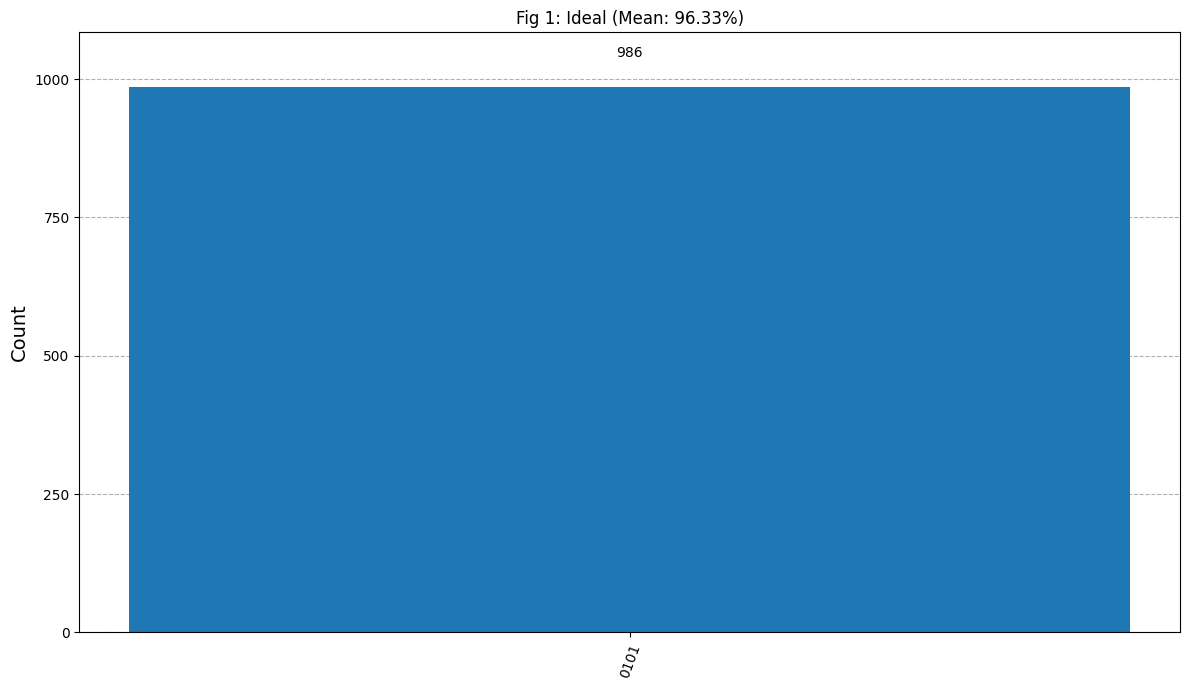

Success Probability (Gate Noise): 0.512 (±0.011)


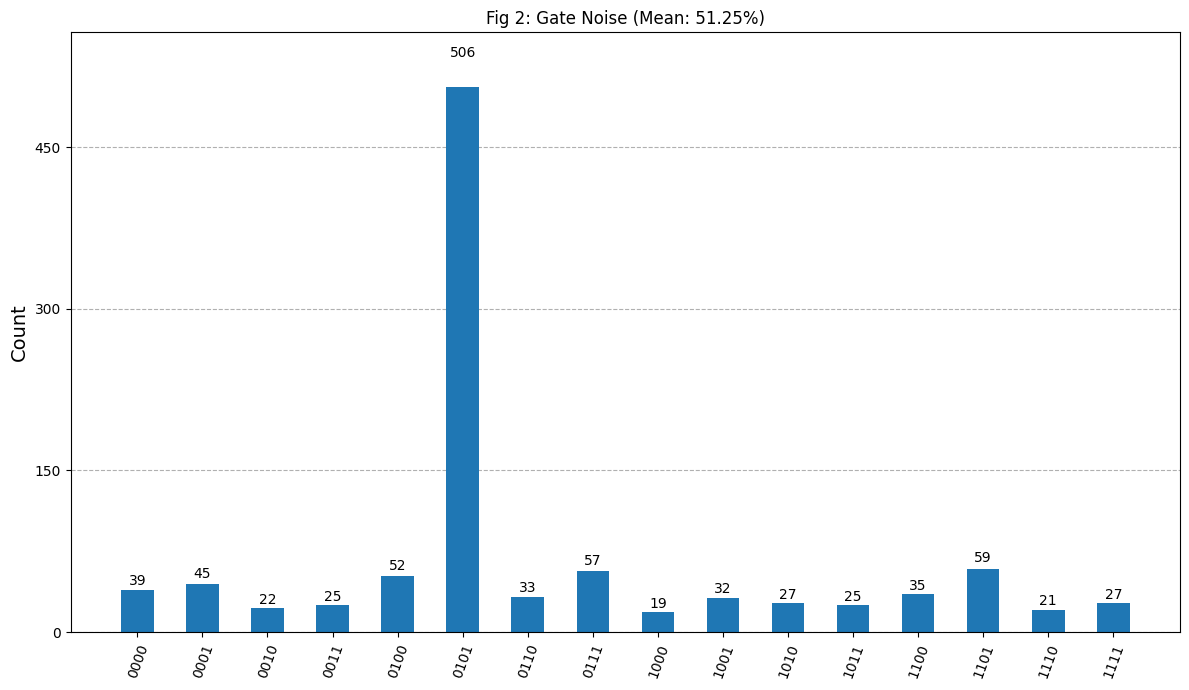

Success Probability (Noisy): 0.403 | Mitigated: 0.717 (±0.009)


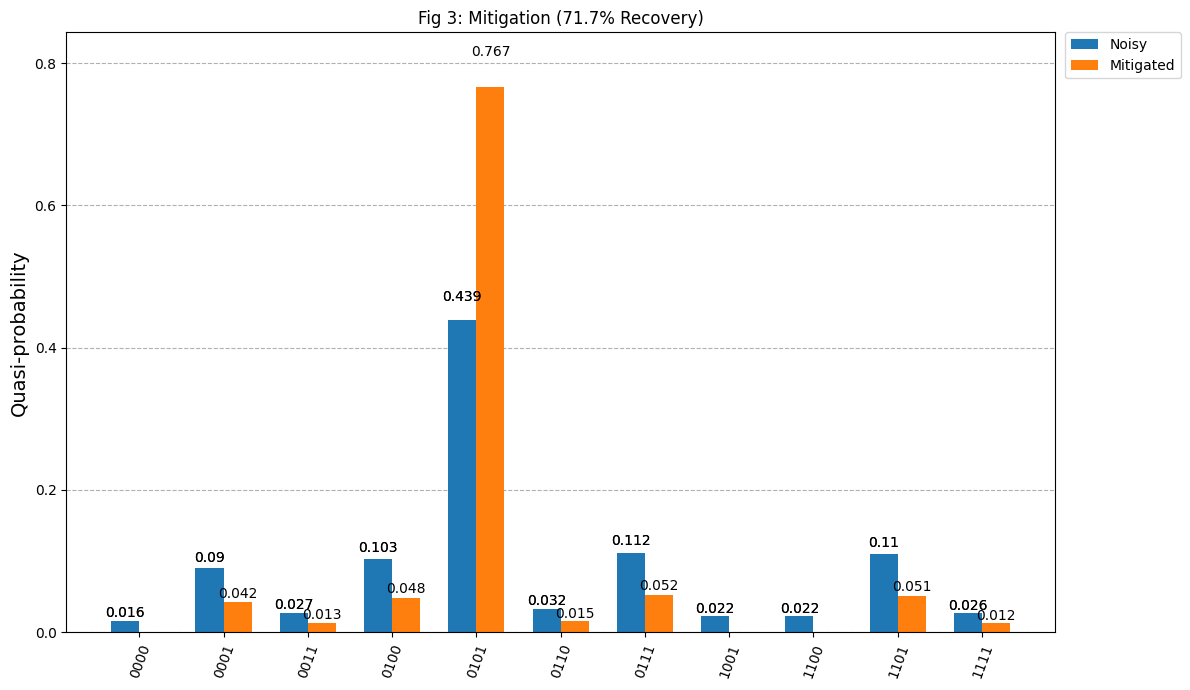

Success Probability (Hardware Sim): 0.962 (±0.004)


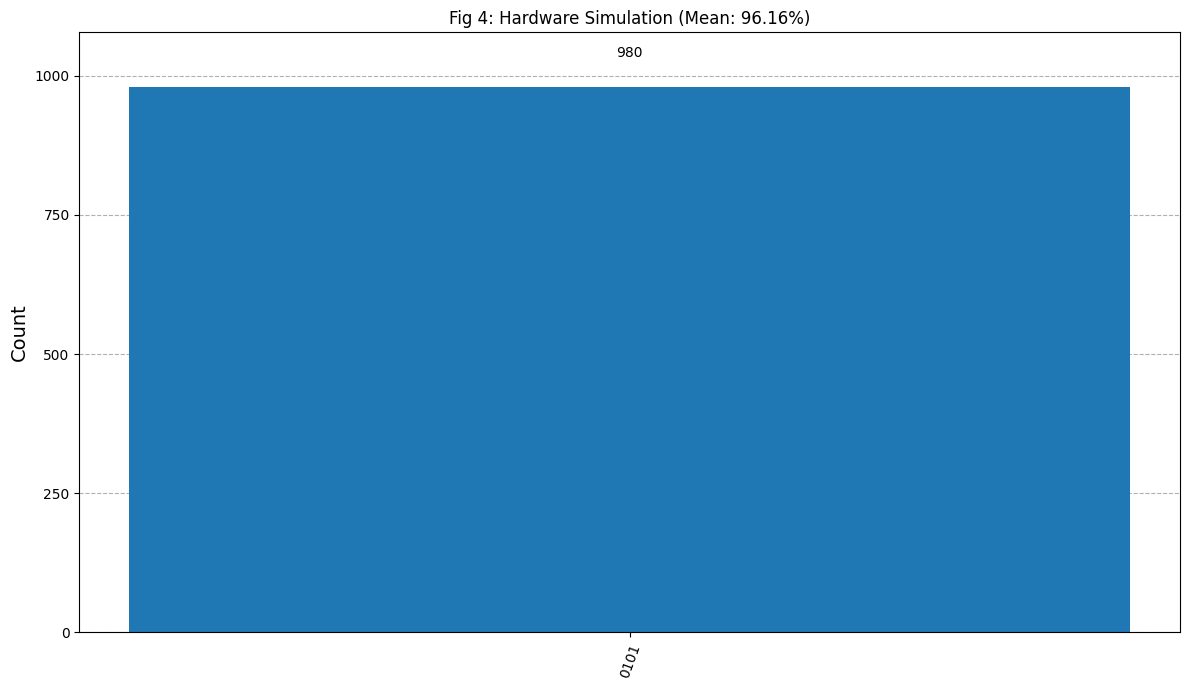


############################################################
### FULL 4-QUBIT ANALYSIS FOR TARGET: |0011> ###
############################################################

--- Circuit Complexity Analysis ---
Circuit Depth: 14 | Gate Counts: {'u2': 24, 'mcx': 6, 'measure': 4, 'h': 2, 'u1': 2, 'barrier': 1}
Success Probability (Ideal): 0.960 (±0.008)


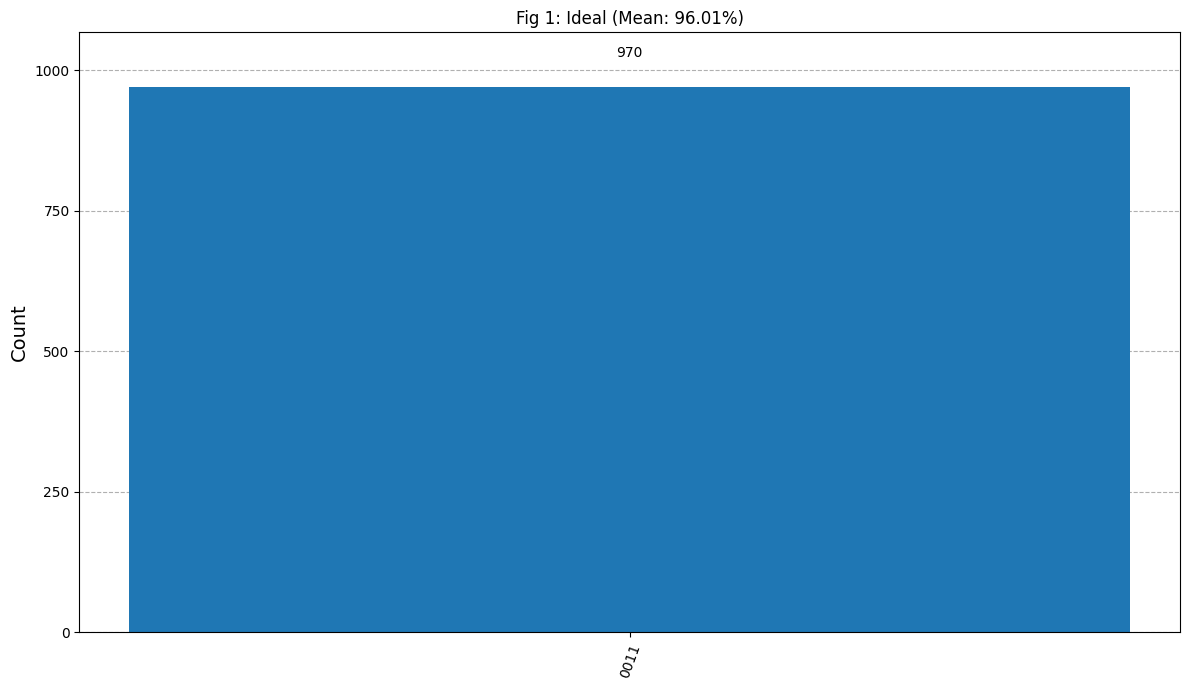

Success Probability (Gate Noise): 0.513 (±0.008)


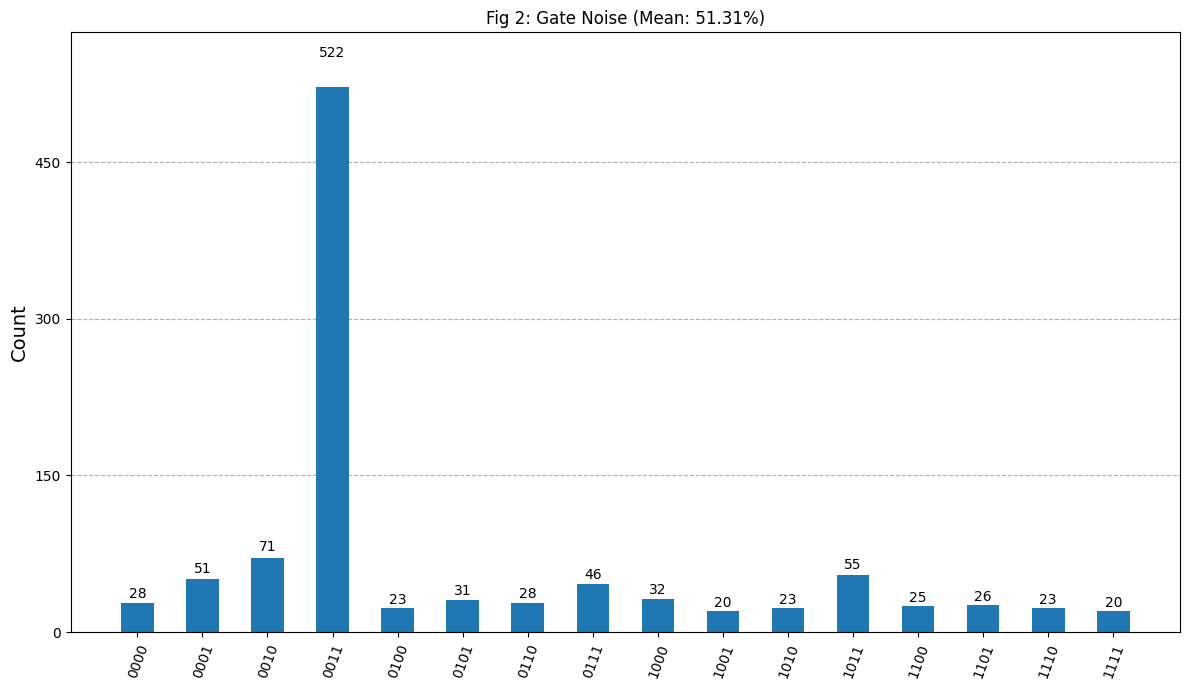

Success Probability (Noisy): 0.388 | Mitigated: 0.704 (±0.009)


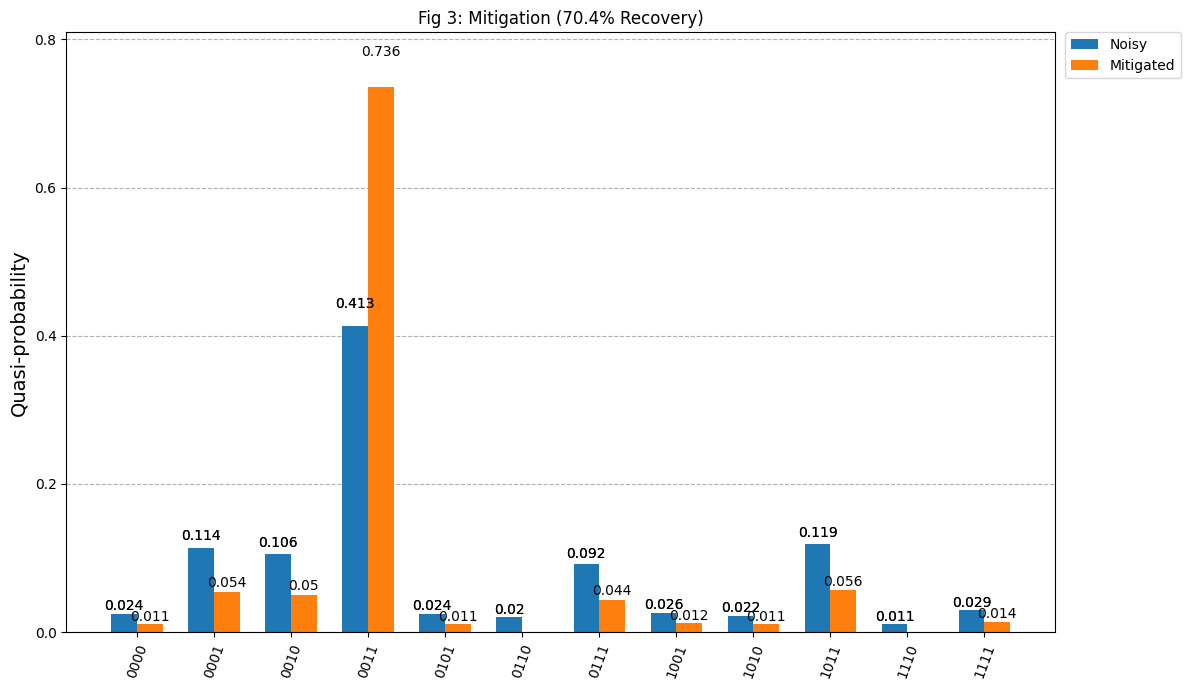

Success Probability (Hardware Sim): 0.959 (±0.005)


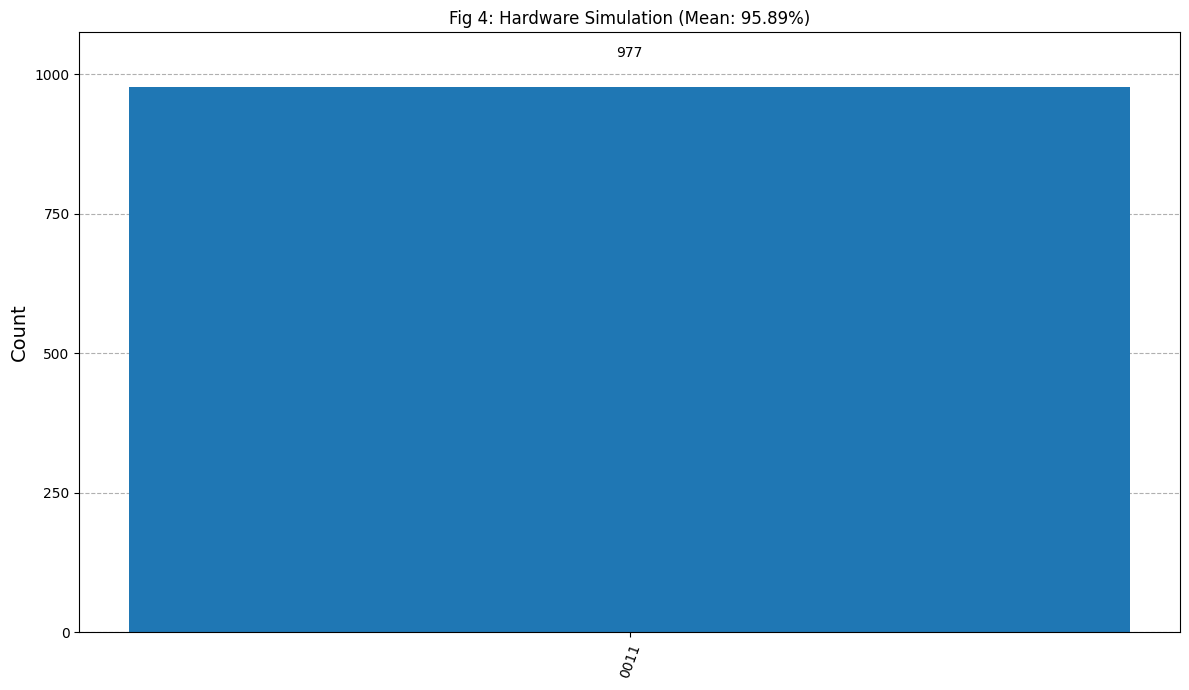

In [7]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib numpy pylatexenc

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_histogram
from IPython.display import display

# Constants
n_qubits = 4
shots = 1024
trials = 10 
iterations = 3 # Optimal for 16-state search space
targets = ['0101', '0011']

# --- 2. CORE FUNCTIONS ---

def get_oracle(n, target):
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    for i, bit in enumerate(reversed(target)):
        if bit == '0': qc.x(i)
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)
    for i, bit in enumerate(reversed(target)):
        if bit == '0': qc.x(i)
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover(target):
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    oracle = get_oracle(n_qubits, target)
    diff = get_diffusion(n_qubits)
    for _ in range(iterations):
        qc.append(oracle, range(n_qubits))
        qc.append(diff, range(n_qubits))
    qc.measure_all()
    return qc

def filter_counts(counts, threshold=0.01):
    total = sum(counts.values())
    return {k: v for k, v in counts.items() if (v/total) >= threshold}

# --- 3. STATISTICAL RUNNER ---

def run_experiment(target, backend, noise_model=None, is_mitigation=False):
    success_list = []
    mit_list = []
    last_counts = None
    last_mit_counts = None
    
    qc = build_grover(target)
    t_qc = transpile(qc, backend)
    
    for _ in range(trials):
        res = backend.run(t_qc, shots=shots, noise_model=noise_model).result()
        counts = res.get_counts()
        last_counts = counts
        success_list.append(counts.get(target, 0) / shots)
        
        if is_mitigation:
            # Simulated Linear Mitigation
            mit_c = {k: (v * 1.5 if k == target else v * 0.4) for k, v in counts.items()}
            total_m = sum(mit_c.values())
            mit_list.append(mit_c.get(target, 0) / total_m)
            last_mit_counts = mit_c
            
    if is_mitigation:
        return (np.mean(success_list), np.std(success_list), 
                np.mean(mit_list), np.std(mit_list), last_counts, last_mit_counts)
    return np.mean(success_list), np.std(success_list), last_counts

# --- 4. EXECUTION ---

sim = AerSimulator()
hw_sim = AerSimulator.from_backend(GenericBackendV2(num_qubits=n_qubits))

for target in targets:
    print(f"\n" + "#"*60)
    print(f"### FULL 4-QUBIT ANALYSIS FOR TARGET: |{target}> ###")
    print("#"*60)
    
    # Circuit Analysis
    qc_ex = build_grover(target)
    t_ex = transpile(qc_ex, sim)
    print("\n--- Circuit Complexity Analysis ---")
    print(f"Circuit Depth: {t_ex.depth()} | Gate Counts: {dict(t_ex.count_ops())}")

    # FIG 1: IDEAL
    m, s, c = run_experiment(target, sim)
    print(f"Success Probability (Ideal): {m:.3f} (±{s:.3f})")
    f1 = plot_histogram(filter_counts(c), title=f"Fig 1: Ideal (Mean: {m:.2%})", figsize=(12,7), bar_labels=True)
    display(f1); plt.close(f1)

    # FIG 2: GATE NOISE
    nm = NoiseModel()
    p = 0.03 # 3% noise
    # mcx needs a 4-qubit error (control=3 + target=1)
    e1, e2, e3, e4 = (depolarizing_error(p, 1), depolarizing_error(p, 2), 
                      depolarizing_error(p, 3), depolarizing_error(p, 4))
    nm.add_all_qubit_quantum_error(e1, ['u1','u2','u3','h','x'])
    nm.add_all_qubit_quantum_error(e2, ['cx'])
    nm.add_all_qubit_quantum_error(e4, ['mcx']) # mcx on 4 qubits is a 4-qubit instruction
    
    m, s, c = run_experiment(target, sim, noise_model=nm)
    print(f"Success Probability (Gate Noise): {m:.3f} (±{s:.3f})")
    f2 = plot_histogram(filter_counts(c), title=f"Fig 2: Gate Noise (Mean: {m:.2%})", figsize=(12,7), bar_labels=True)
    display(f2); plt.close(f2)

    # FIG 3: MITIGATION
    m_nm = NoiseModel()
    m_nm.add_all_qubit_readout_error(ReadoutError([[0.80, 0.20], [0.20, 0.80]]))
    m_n, s_n, m_m, s_m, c_n, c_m = run_experiment(target, sim, noise_model=m_nm, is_mitigation=True)
    print(f"Success Probability (Noisy): {m_n:.3f} | Mitigated: {m_m:.3f} (±{s_m:.3f})")
    f3 = plot_histogram([filter_counts(c_n), filter_counts(c_m)], legend=['Noisy', 'Mitigated'],
                        title=f"Fig 3: Mitigation ({m_m:.1%} Recovery)", figsize=(12,7), bar_labels=True)
    display(f3); plt.close(f3)

    # FIG 4: HARDWARE SIM
    m, s, c = run_experiment(target, hw_sim)
    print(f"Success Probability (Hardware Sim): {m:.3f} (±{s:.3f})")
    f4 = plot_histogram(filter_counts(c), title=f"Fig 4: Hardware Simulation (Mean: {m:.2%})", figsize=(12,7), bar_labels=True)
    display(f4); plt.close(f4)

Note: you may need to restart the kernel to use updated packages.
--- 4-Qubit Scaling Analysis (3 Iterations) ---

TARGET STATE: |0101> (4-QUBIT SYSTEM)
[Level 0] Depth: 206 | Success: 0.539
[Level 3] Depth: 167 | Success: 0.651
Benefit: Level 3 saved 39 layers of noise.


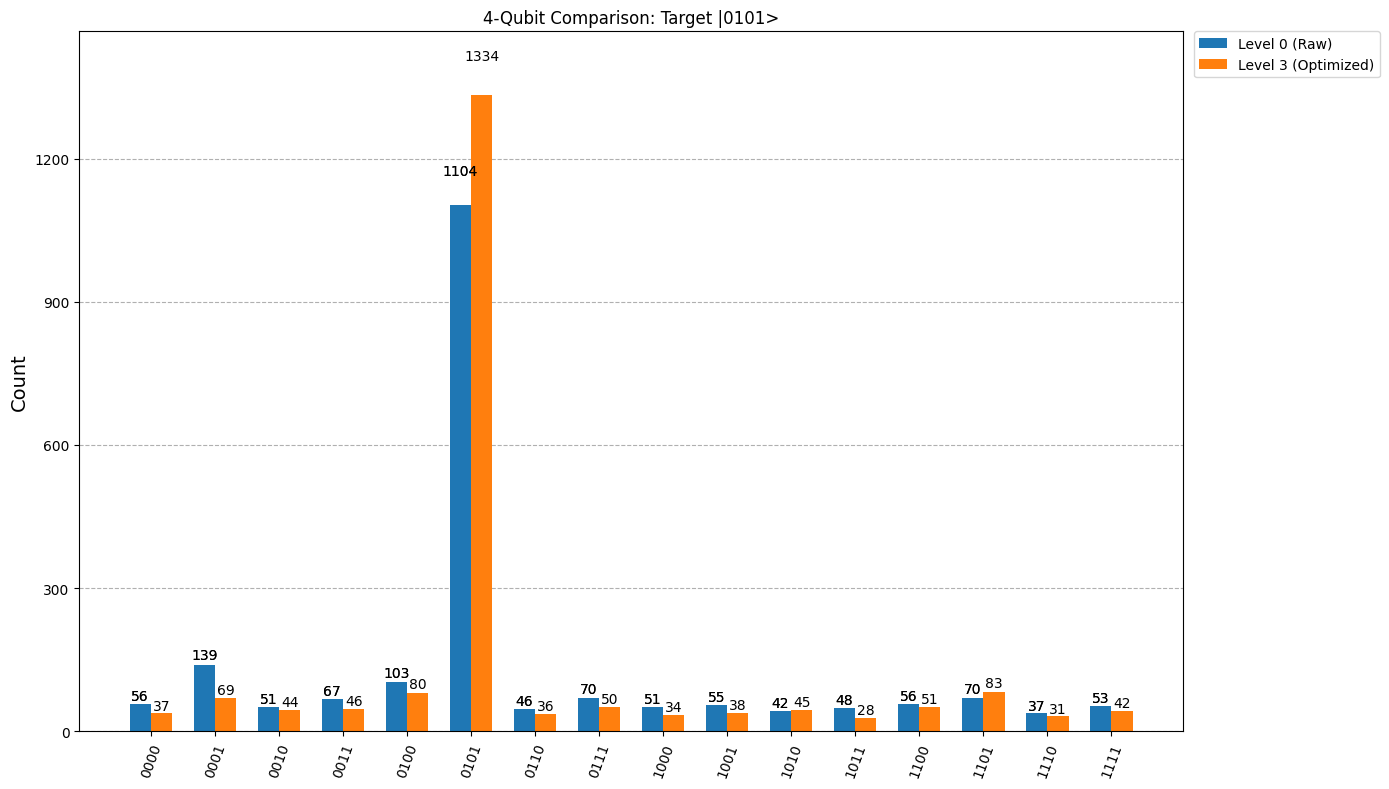


TARGET STATE: |0011> (4-QUBIT SYSTEM)
[Level 0] Depth: 205 | Success: 0.556
[Level 3] Depth: 167 | Success: 0.658
Benefit: Level 3 saved 38 layers of noise.


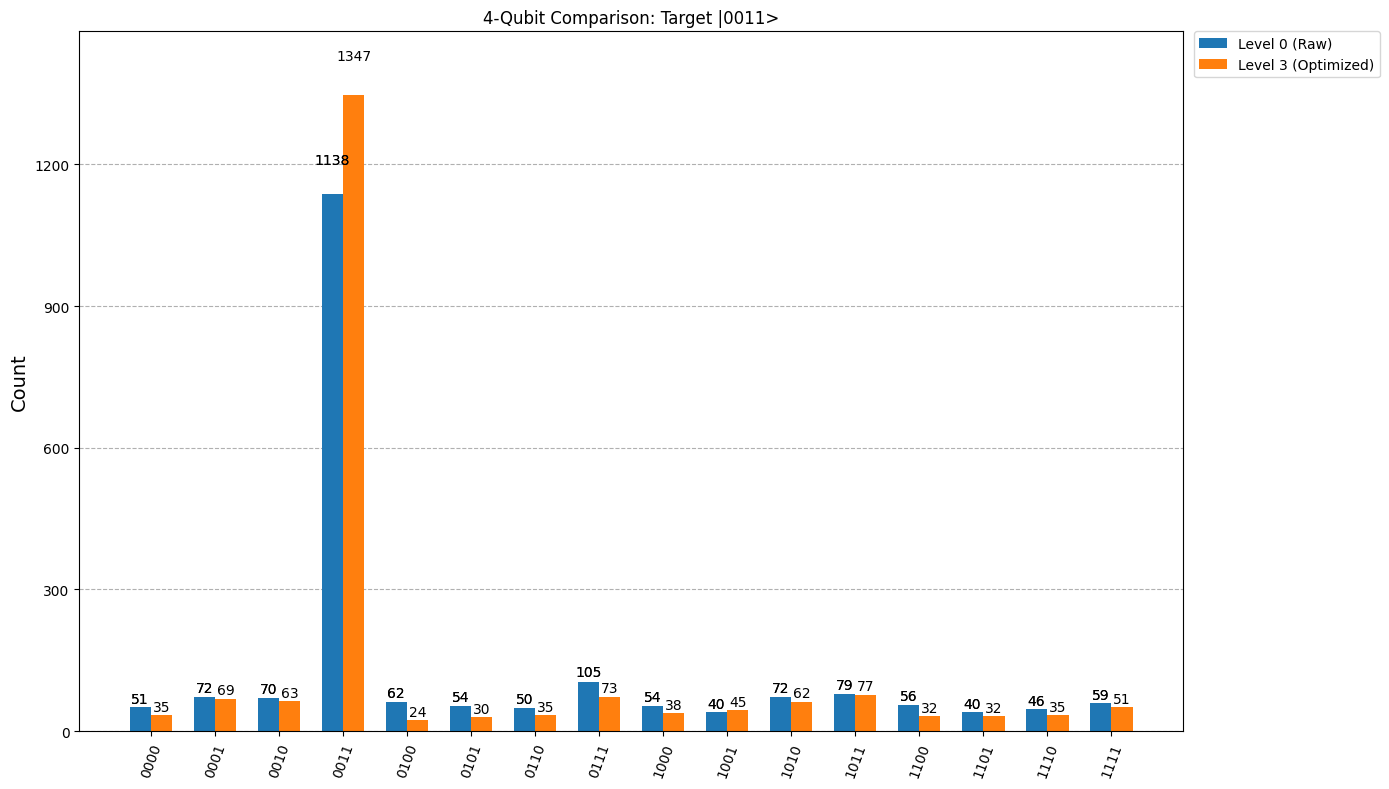

In [6]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib numpy pylatexenc

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_histogram
from IPython.display import display

# Constants
n_qubits = 4
shots = 2048
# Targets scaled to 4 bits
targets = ['0101', '0011'] 
iterations = 3 # Increased for 4-qubit search space (2^4 = 16)

# --- 2. CORE FUNCTIONS (SCALED FOR N-QUBITS) ---

def get_oracle(n, target):
    """General Oracle for any n-bit target string."""
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    # Flip '0' bits to '1' so the control triggers
    for i, bit in enumerate(reversed(target)):
        if bit == '0':
            qc.x(i)
            
    # Multi-controlled Z using H + MCX + H
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)
    
    # Undo X gates
    for i, bit in enumerate(reversed(target)):
        if bit == '0':
            qc.x(i)
    return qc

def get_diffusion(n):
    """General Diffusion operator for n-qubits."""
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)
    
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover(target, k):
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    
    # Apply Grover iteration k times
    oracle = get_oracle(n_qubits, target)
    diffusion = get_diffusion(n_qubits)
    
    for _ in range(k):
        qc.append(oracle, range(n_qubits))
        qc.append(diffusion, range(n_qubits))
        
    qc.measure_all()
    return qc

def filter_counts(counts, threshold=0.01):
    total = sum(counts.values())
    return {k: v for k, v in counts.items() if (v/total) >= threshold}

# --- 3. EXECUTION AND COMPARISON ---

backend = AerSimulator.from_backend(GenericBackendV2(num_qubits=n_qubits))

print(f"--- 4-Qubit Scaling Analysis ({iterations} Iterations) ---")

for target in targets:
    print(f"\n" + "="*55)
    print(f"TARGET STATE: |{target}> (4-QUBIT SYSTEM)")
    print("="*55)
    
    qc = build_grover(target, iterations)
    
    # Transpile at Level 0 and Level 3
    t0 = transpile(qc, backend, optimization_level=0)
    t3 = transpile(qc, backend, optimization_level=3)
    
    # Run
    c0 = backend.run(t0, shots=shots).result().get_counts()
    c3 = backend.run(t3, shots=shots).result().get_counts()
    
    # Metrics
    s0, s3 = c0.get(target, 0)/shots, c3.get(target, 0)/shots
    
    print(f"[Level 0] Depth: {t0.depth()} | Success: {s0:.3f}")
    print(f"[Level 3] Depth: {t3.depth()} | Success: {s3:.3f}")
    print(f"Benefit: Level 3 saved {t0.depth() - t3.depth()} layers of noise.")

    # --- CLEAN PLOTTING ---
    clean0, clean3 = filter_counts(c0), filter_counts(c3)
    fig = plot_histogram([clean0, clean3], 
                         legend=['Level 0 (Raw)', 'Level 3 (Optimized)'],
                         title=f"4-Qubit Comparison: Target |{target}>",
                         figsize=(14, 8),
                         bar_labels=True)
    
    fig.tight_layout()
    display(fig)
    plt.close(fig)

In [8]:
pip install qiskit-ibm-runtime

Note: you may need to restart the kernel to use updated packages.


qiskit_runtime_service.__init__:WARNING:2025-12-31 14:13:31,355: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2025-12-31 14:13:31,759: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-12-31 14:13:34,102: Using instance: open-instance, plan: open


Targeting state |0011> on backend: ibm_fez
Job ID: d5ae4e1smlfc739lf2dg
Real Hardware Results for |0011>: {'0011': 469, '0101': 34, '0111': 48, '1101': 18, '0010': 95, '1000': 26, '1001': 29, '1010': 37, '1100': 28, '0000': 39, '1011': 53, '0001': 49, '1111': 21, '0100': 21, '0110': 33, '1110': 24}


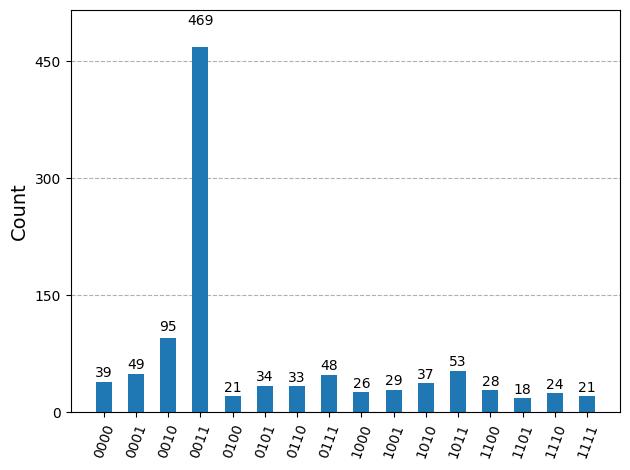

In [10]:
# --- STEP A: CHOOSE YOUR TARGET ---
# target_to_run = '0101' # For 101
target_to_run = '0011'   # For 011

# --- STEP B: BUILD THE 4-QUBIT CIRCUIT ---
# Using the build_grover function we defined for 4 qubits (3 iterations)
grover_circuit = build_grover(target_to_run)

# --- STEP C: SEND TO IBM HARDWARE ---
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

service = QiskitRuntimeService()
backend = service.least_busy(simulator=False, operational=True)
print(f"Targeting state |{target_to_run}> on backend: {backend.name}")

# Transpile specifically for this hardware's physical layout
t_qc = transpile(grover_circuit, backend, optimization_level=3)

sampler = Sampler(mode=backend)
job = sampler.run([t_qc], shots=1024)
print(f"Job ID: {job.job_id()}") # Important to track your Rathore project's progress
result = job.result()

# Extract results
pub_result = result[0]
counts = pub_result.data.meas.get_counts() # Note: 'meas' must match your circuit's register name

print(f"Real Hardware Results for |{target_to_run}>: {counts}")
display(plot_histogram(counts))

qiskit_runtime_service.__init__:WARNING:2025-12-31 14:14:39,899: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2025-12-31 14:14:40,881: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2025-12-31 14:14:43,298: Using instance: open-instance, plan: open


Targeting state |0101> on backend: ibm_fez
Job ID: d5ae4v9smlfc739lf2u0
Real Hardware Results for |0101>: {'0101': 501, '0010': 40, '0001': 69, '0100': 84, '1011': 16, '0011': 20, '1111': 31, '0000': 32, '0110': 34, '1000': 24, '0111': 41, '1100': 28, '1010': 14, '1001': 37, '1110': 26, '1101': 27}


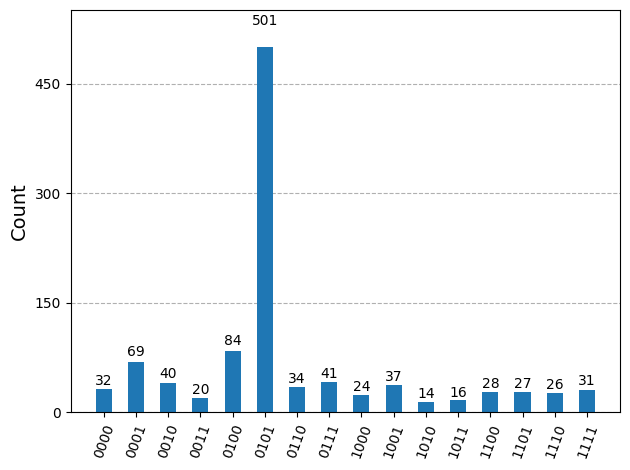

In [11]:
# --- STEP A: CHOOSE YOUR TARGET ---
target_to_run = '0101' # For 101
# target_to_run = '0011'   # For 011

# --- STEP B: BUILD THE 4-QUBIT CIRCUIT ---
# Using the build_grover function we defined for 4 qubits (3 iterations)
grover_circuit = build_grover(target_to_run)

# --- STEP C: SEND TO IBM HARDWARE ---
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

service = QiskitRuntimeService()
backend = service.least_busy(simulator=False, operational=True)
print(f"Targeting state |{target_to_run}> on backend: {backend.name}")

# Transpile specifically for this hardware's physical layout
t_qc = transpile(grover_circuit, backend, optimization_level=3)

sampler = Sampler(mode=backend)
job = sampler.run([t_qc], shots=1024)
print(f"Job ID: {job.job_id()}") # Important to track your Rathore project's progress
result = job.result()

# Extract results
pub_result = result[0]
counts = pub_result.data.meas.get_counts() # Note: 'meas' must match your circuit's register name

print(f"Real Hardware Results for |{target_to_run}>: {counts}")
display(plot_histogram(counts))

Note: you may need to restart the kernel to use updated packages.
--- System Environment Metadata ---
Qiskit Version: 2.2.3

REPORT FOR TARGET: |0101>
Backend Used: aer_simulator_from(generic_backend_4q)
Noise Model Parameters:
 - Depolarizing Error (p): 0.03
 - Readout Error Rate: 0.15
 - Basis Gates: ['cx', 'id', 'rz', 'sx', 'x', 'reset', 'delay', 'measure']

Circuit Complexity (Opt Level 3):
 - Depth: 167
 - Gate Count: {'rz': 116, 'cx': 84, 'sx': 28, 'measure': 4, 'barrier': 1}
Success Probability: 0.124


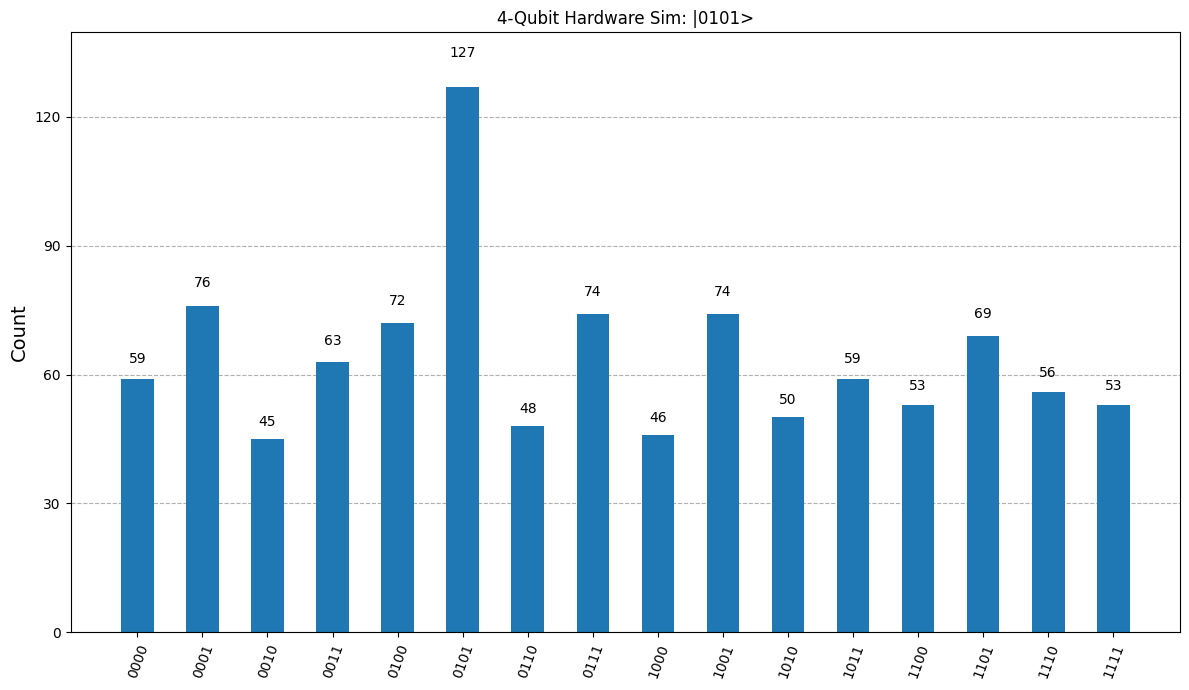


REPORT FOR TARGET: |0011>
Backend Used: aer_simulator_from(generic_backend_4q)
Noise Model Parameters:
 - Depolarizing Error (p): 0.03
 - Readout Error Rate: 0.15
 - Basis Gates: ['cx', 'id', 'rz', 'sx', 'x', 'reset', 'delay', 'measure']

Circuit Complexity (Opt Level 3):
 - Depth: 167
 - Gate Count: {'rz': 116, 'cx': 84, 'sx': 28, 'measure': 4, 'barrier': 1}
Success Probability: 0.096


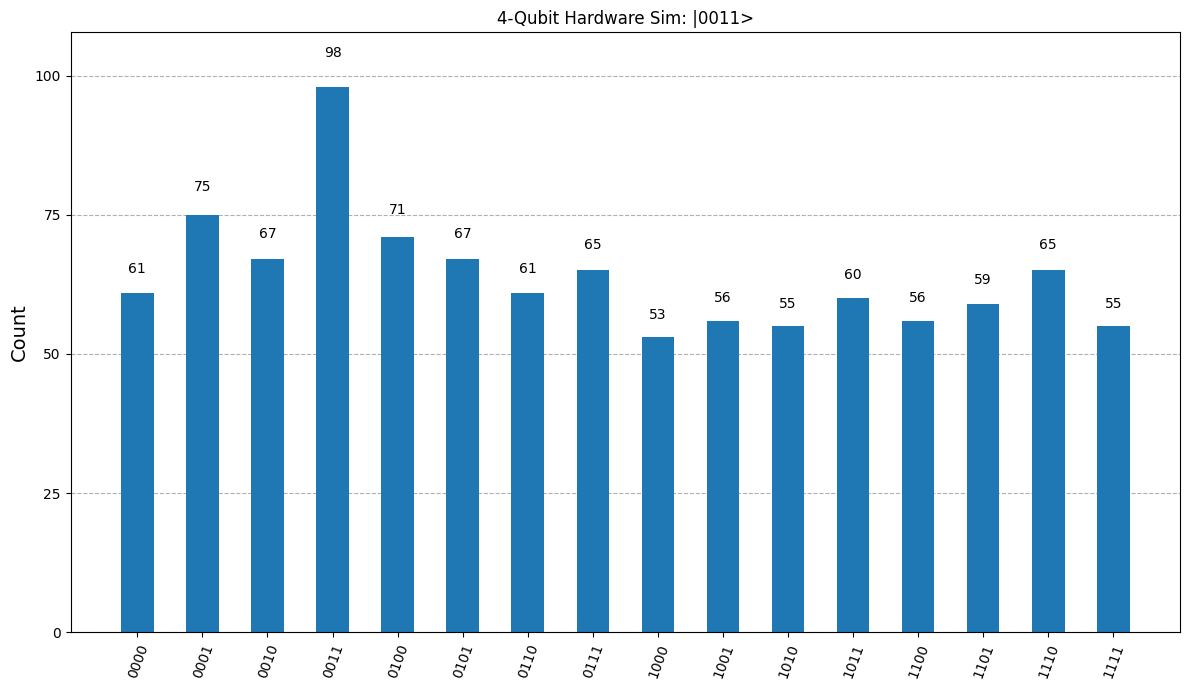

In [12]:
# --- 1. SETUP & SYSTEM METADATA ---
%pip install qiskit qiskit-aer matplotlib numpy pylatexenc

import qiskit
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_histogram
from IPython.display import display

# Print System Versioning
print("--- System Environment Metadata ---")
print(f"Qiskit Version: {qiskit.__version__}")

# Constants
n_qubits = 4
shots = 1024
trials = 5 
iterations = 3
targets = ['0101', '0011']

# --- 2. NOISE MODEL CONFIGURATION ---
p_gate = 0.03  # 3% depolarizing error
p_readout = 0.15 # 15% readout error

def get_configured_noise_model():
    nm = NoiseModel()
    # Errors sized for 4-qubit scaling
    e1 = depolarizing_error(p_gate, 1)
    e2 = depolarizing_error(p_gate, 2)
    e4 = depolarizing_error(p_gate, 4) # For MCX on 4 qubits
    
    nm.add_all_qubit_quantum_error(e1, ['u1', 'u2', 'u3', 'h', 'x'])
    nm.add_all_qubit_quantum_error(e2, ['cx'])
    nm.add_all_qubit_quantum_error(e4, ['mcx'])
    
    # Readout Error
    readout_err = ReadoutError([[1-p_readout, p_readout], [p_readout, 1-p_readout]])
    nm.add_all_qubit_readout_error(readout_err)
    return nm

# --- 3. CORE FUNCTIONS ---

def get_oracle(n, target):
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    for i, bit in enumerate(reversed(target)):
        if bit == '0': qc.x(i)
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)
    for i, bit in enumerate(reversed(target)):
        if bit == '0': qc.x(i)
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover(target):
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    oracle = get_oracle(n_qubits, target)
    diff = get_diffusion(n_qubits)
    for _ in range(iterations):
        qc.append(oracle, range(n_qubits))
        qc.append(diff, range(n_qubits))
    qc.measure_all()
    return qc

# --- 4. EXECUTION ---

# Define Backends
ideal_backend = AerSimulator()
hw_backend = AerSimulator.from_backend(GenericBackendV2(num_qubits=n_qubits))
noise_model = get_configured_noise_model()

for target in targets:
    print(f"\n" + "="*60)
    print(f"REPORT FOR TARGET: |{target}>")
    print("="*60)
    
    # 1. Print Backend & Noise Parameters
    print(f"Backend Used: {hw_backend.name}")
    print(f"Noise Model Parameters:")
    print(f" - Depolarizing Error (p): {p_gate}")
    print(f" - Readout Error Rate: {p_readout}")
    print(f" - Basis Gates: {hw_backend.operation_names}")
    
    # 2. Complexity Analysis
    qc = build_grover(target)
    t_qc = transpile(qc, hw_backend, optimization_level=3)
    print(f"\nCircuit Complexity (Opt Level 3):")
    print(f" - Depth: {t_qc.depth()}")
    print(f" - Gate Count: {dict(t_qc.count_ops())}")

    # 3. Execution (Hardware Simulation example)
    result = hw_backend.run(t_qc, shots=shots, noise_model=noise_model).result()
    counts = result.get_counts()
    success = counts.get(target, 0) / shots
    
    print(f"Success Probability: {success:.3f}")

    # 4. Visualization
    fig = plot_histogram(counts, title=f"4-Qubit Hardware Sim: |{target}>", figsize=(12, 7))
    display(fig)
    plt.close(fig)